# Лабораторный практикум по курсу «Синтез Речи», Университет ИТМО, 2026
**Лабораторная работа №3.** Транскрипция

**Цель работы:** Разработка модуля преобразования графем в фонемы (G2P) на русском языке, подготовка фонетической транскрипции для обучения моделей.
**Выполнила** Иванова Мария Кирилловна  
**Группа** М4121  
**Преподаватели** Рыбин Сергей Витальевич, Чирковский Артем

In [12]:
import os
import re
import torch
import rules
import importlib
import numpy as np
import unicodedata
import pandas as pd
import subprocess, sys
importlib.reload(rules)
from collections import Counter
import matplotlib.pyplot as plt

## 1. Предобработка фонетических данных
*(выполнен ранее, артефакты в `labs/lab3_g2p/data/`)*

## 2. Разведочный анализ фонемного инвентаря

#### **Вопрос 1.** Какие фонемы представлены в корпусе? Как они соотносятся с IPA? Какая средняя длительность и вариативность длительности фонем?

`data/phone_stats.csv` - сводка по фонемам, собранная из оригинальных TextGrid-ов (скрипт `explore_inventory.py`).

In [ ]:
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 200)

stats = pd.read_csv('data/phone_stats.csv')
target = [l.strip() for l in open('../../common/phones_mfa.txt') if l.strip()]

print(f'Фонем в статистике: {len(stats)}')
print(f'Целевой инвентарь: {len(target)}')
print(f'Всего инстансов фонем в корпусе: {stats["count"].sum():,}')

stats.head(20)

Фонем в статистике: 90
Целевой инвентарь: 56
Всего инстансов фонем в корпусе: 1,488,456


,phone,count,total_s,mean_s,std_s,min_s,max_s,in_target
0,ɪ,115517,2351.317752,0.020355,0.065745,0.005782,4.310000,True
1,ə,108045,4313.929279,0.039927,0.035038,0.004943,0.750000,True
2,ɐ,74937,4806.455058,0.064140,0.022075,0.010000,0.990000,True
3,a,63780,5671.208771,0.088918,0.036205,0.010000,0.690000,True
4,<SIL>,62431,8699.469299,0.139345,0.176720,0.024943,15.114989,True
5,t̪,62173,4905.286922,0.078897,0.032291,0.010000,0.500000,True
6,j,55664,3644.481715,0.065473,0.039439,0.006259,0.470000,True
7,n̪,51120,3371.945680,0.065961,0.030135,0.006259,0.540000,True
8,e,49893,3668.776505,0.073533,0.035246,0.007551,0.660000,True
9,r,45767,2852.439796,0.062325,0.027827,0.010000,0.480000,True


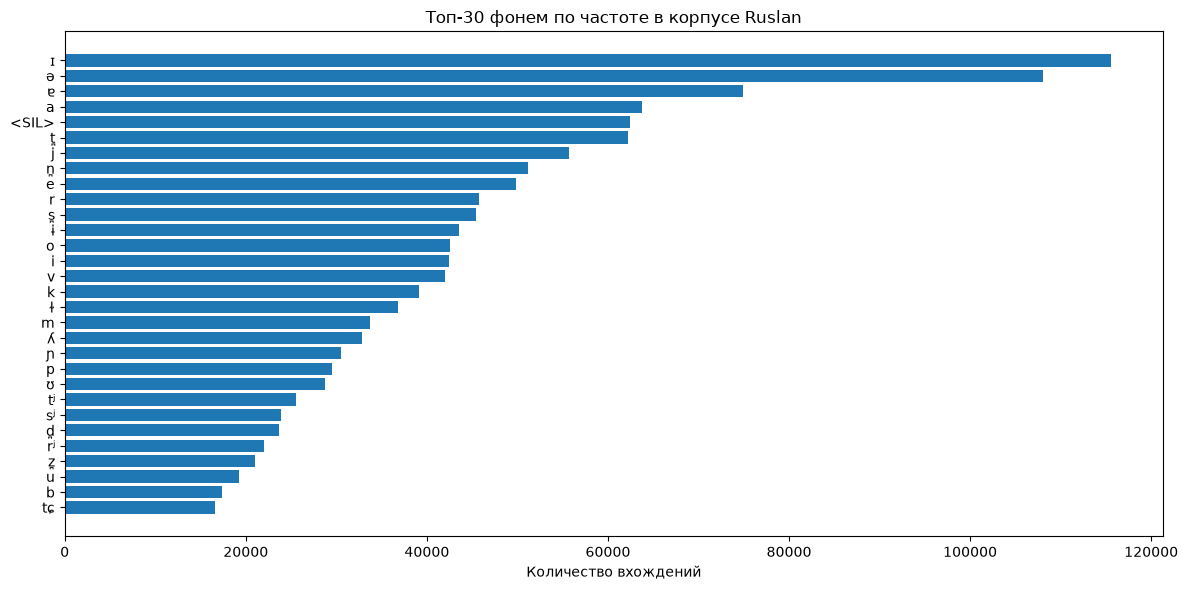

In [ ]:
top = stats.nlargest(30, 'count')
fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(top['phone'][::-1], top['count'][::-1])
ax.set_xlabel('Количество вхождений')
ax.set_title('Топ-30 фонем по частоте в корпусе Ruslan')
plt.tight_layout()
plt.show()

Как фонемы соотносятся с IPA

In [ ]:
ipa_map = {
    # гласные
    'a': '[a] — ударный открытый передне-средний',
    'æ': '[æ] — ударный передний (после мягких)',
    'e': '[e] — ударный передне-средний (закрытый)',
    'ɛ': '[ɛ] — ударный передний открытый',
    'i': '[i] — ударный передний верхний',
    'o': '[o] — ударный задний средний',
    'u': '[u] — ударный задний верхний',
    'ɨ': '[ɨ] — редуцированный центральный (после тв.)',
    'ɪ': '[ɪ] — редуцированный передний (после мягк.)',
    'ɐ': '[ɐ] — 1-я степень редукции (безударный a/o)',
    'ə': '[ə] — 2-я степень редукции (безударный a/o)',
    'ɵ': '[ɵ] — редуцированный о-образный (после мягк.)',
    'ʉ': '[ʉ] — редуцированный u-образный (после мягк.)',
    'ʊ': '[ʊ] — редуцированный u-образный (после тв.)',
    # согласные
    'b': '[b] — звонкий взрывной губной',
    'bʲ': '[bʲ] — мягкий',
    'p': '[p] — глухой взрывной губной',
    'pʲ': '[pʲ] — мягкий',
    'd̪': '[d̪] — звонкий зубной взрывной',
    'dʲ': '[dʲ] — мягкий',
    't̪': '[t̪] — глухой зубной взрывной',
    'tʲ': '[tʲ] — мягкий',
    'ɡ': '[ɡ] — звонкий велярный взрывной',
    'k': '[k] — глухой велярный',
    'v': '[v] — звонкий губно-зубной',
    'vʲ': '[vʲ] — мягкий',
    'f': '[f] — глухой губно-зубной',
    'fʲ': '[fʲ] — мягкий',
    'z̪': '[z̪] — звонкий зубной щелевой',
    'zʲ': '[zʲ] — мягкий',
    's̪': '[s̪] — глухой зубной щелевой',
    'sʲ': '[sʲ] — мягкий',
    'ʐ': '[ʐ] — звонкий ретрофлексный',
    'ʂ': '[ʂ] — глухой ретрофлексный',
    'ɕ': '[ɕ] — мягкий шипящий (щ)',
    'ʑ': '[ʑ] — звонкий мягкий шипящий (жж)',
    'tɕ': '[tɕ] — мягкая аффриката (ч)',
    'tʂ': '[tʂ] — твёрдая аффриката (дж/ч)',
    'dʐ': '[dʐ] — звонкая аффриката (дж)',
    't̪s̪': '[t̪s̪] — зубная аффриката (ц)',
    'd̪z̪': '[d̪z̪] — звонкая (дз)',
    'm': '[m] — носовой губной',
    'mʲ': '[mʲ] — мягкий',
    'n̪': '[n̪] — носовой зубной',
    'ɲ': '[ɲ] — носовой мягкий',
    'r': '[r] — дрожащий',
    'rʲ': '[rʲ] — мягкий',
    'l': '[l] — боковой',
    'ɫ': '[ɫ] — тёмный (веляризованный)',
    'ʎ': '[ʎ] — мягкий боковой',
    'j': '[j] — аппроксимант й',
    'x': '[x] — глухой велярный щелевой',
    'ɣ': '[ɣ] — звонкий велярный щелевой',
    'c': '[c] — глухой палатальный взрывной',
    'ɟ': '[ɟ] — звонкий палатальный взрывной',
    'ç': '[ç] — глухой палатальный щелевой',
    '<SIL>': 'пауза',
    'spn': 'speaking noise (артефакт)',
}

rows = []
for _, r in stats.iterrows():
    rows.append({
        'phone': r.phone,
        'in_target': r.phone in target or r.phone in ('<SIL>', 'spn'),
        'count': r['count'],
        'mean_s': round(r.mean_s, 4),
        'std_s': round(r.std_s, 4),
        'ipa': ipa_map.get(r.phone, '—'),
    })
inv = pd.DataFrame(rows).sort_values('count', ascending=False).reset_index(drop=True)
inv.head(90)

,phone,in_target,count,mean_s,std_s,ipa
0,ɪ,True,115517,0.0204,0.0657,[ɪ] — редуцированный передний (после мягк.)
1,ə,True,108045,0.0399,0.0350,[ə] — 2-я степень редукции (безударный a/o)
2,ɐ,True,74937,0.0641,0.0221,[ɐ] — 1-я степень редукции (безударный a/o)
3,a,True,63780,0.0889,0.0362,[a] — ударный открытый передне-средний
4,<SIL>,True,62431,0.1393,0.1767,пауза
5,t̪,True,62173,0.0789,0.0323,[t̪] — глухой зубной взрывной
6,j,True,55664,0.0655,0.0394,[j] — аппроксимант й
7,n̪,True,51120,0.0660,0.0301,[n̪] — носовой зубной
8,e,True,49893,0.0735,0.0352,[e] — ударный передне-средний (закрытый)
9,r,True,45767,0.0623,0.0278,[r] — дрожащий


Длительность и вариативность

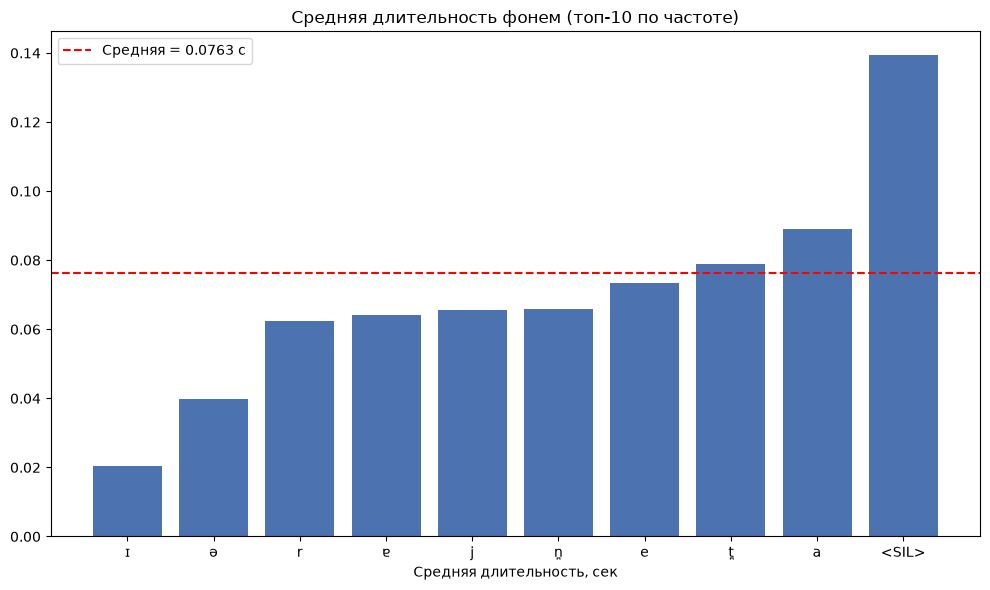

Общая средняя длительность фонемы: 0.0763 сек
Самая длинная реальная фонема: tʂ (0.2250 сек)
Самая короткая фонема: ɪ (0.0204 сек)


In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
top = inv.head(10).sort_values('mean_s')
ax.bar(top['phone'], top['mean_s'], color='#4c72b0')
ax.axhline(np.average(inv['mean_s'], weights=inv['count']),
           color='red', linestyle='--',
           label=f'Средняя = {np.average(inv["mean_s"], weights=inv["count"]):.4f} с')
ax.set_xlabel('Средняя длительность, сек')
ax.set_title('Средняя длительность фонем (топ-10 по частоте)')
ax.legend()
plt.tight_layout()
plt.show()

print('Общая средняя длительность фонемы:',
      f'{np.average(inv["mean_s"], weights=inv["count"]):.4f} сек')
clean = inv[~inv.phone.isin(['spn', '<SIL>'])]
print('Самая длинная реальная фонема:',
      clean.loc[clean.mean_s.idxmax(), 'phone'],
      f'({clean.mean_s.max():.4f} сек)')
print('Самая короткая фонема:', inv.loc[inv.mean_s.idxmin(), 'phone'],
      f'({inv.mean_s.min():.4f} сек)')

In [ ]:
stats = pd.read_csv('data/phone_stats.csv')
target = [l.strip() for l in open('../../common/phones_mfa.txt') if l.strip()]

observed_target = set(stats.phone) & set(target)
missing = [p for p in target if p not in observed_target]
print('Целевых фонем, отсутствующих в корпусе:', len(missing))
print(missing)

Целевых фонем, отсутствующих в корпусе: 3
['dʐ', 'ɕ', 'ʑ']


`phone_stats.csv` посчитан по сырым TextGrid-ам (скрипт`explore_inventory.py`), то есть до чистки `spn` и до схлопывания `Xː`.
Поэтому 3 целевые фонемы (`ɕ`, `dʐ`, `ʑ`) в нём отсутствуют в короткой форме, но присутствуют в долгой (`ɕː`, `dʐː`, `ʑː`). Это ожидаемо: в разметке MFA они записаны как долгие, а в `prepare_lexicon.py` схлопываются в короткие.

- В корпусе встречается 90 уникальных меток; из них 54 - целевые фонемы + `<SIL>` + `spn` + 36 «долгие» (`Xː`) и редкие формы.
- Самые частые - гласные: `ɪ` (115 517), `ə` (108 045), `ɐ` (74 937), `a` (63 780). 
- `<SIL>` на 5-м месте.
- Средняя длительность фонемы в корпусе 0.0763 с.
- Самая короткая фонема - `ɪ` (0.0204 с), самая длинная (не считая `<SIL>`) - tʂ (0.2250 сек).

**Соотношение с IPA:** MFA-инвентарь близок к IPA, но использует диакритики:
зубные `s̪ t̪ z̪ d̪`, мягкие `tʲ dʲ sʲ zʲ`, ретрофлексные `ʂ ʐ tʂ`,
шипящие `ɕ ʑ`, аффрикаты `tɕ dʐ t̪s̪ d̪z̪`.
Важное отличие - редукция гласных (`ɐ ə ɪ ʊ ɵ ʉ`).

#### **Вопрос 2.** Определите самые редкие фонемы в корпусе: Можно ли с ними что-то сделать?

In [ ]:
tok = pd.read_csv('data/tokens_phones.csv', sep='|', quoting=3)
tok['phones'] = tok.phones.fillna('').astype(str)

cnt = Counter()
for ph in tok.phones:
    for p in ph.split():
        cnt[p] += 1

print(f'Уникальных фонем в очищенном корпусе: {len(cnt)}')
print(f'Всего инстансов: {sum(cnt.values()):,}')
print()
print('Топ-10:', cnt.most_common(10))
print()
print('Редкие (≤ 100):', [(p, c) for p, c in cnt.items() if c <= 100])

Уникальных фонем в очищенном корпусе: 55
Всего инстансов: 1,237,643

Топ-10: [('ɪ', 100361), ('ə', 93835), ('ɐ', 65301), ('a', 55253), ('t̪', 54206), ('n̪', 48333), ('j', 48286), ('e', 43333), ('s̪', 41180), ('r', 39990)]

Редкие (≤ 100): [('ʑ', 18), ('ɣ', 18), ('d̪z̪', 1)]


### Редкие фонемы

В очищенном корпусе (`tokens_phones.csv`, 1 237 643 инстанса) Встречается весь набор фонем. Всего 3 фонемы встречаются реже 100 раз:

| Фонема | Количество | Описание |
|---|---|---|
| `d̪z̪` | 1 | звонкая «дз» (дзюдо, меццо) |
| `ɣ` | 18 | звонкий щелевой (в «Бог» - [boɣ]) |
| `ʑ` | 18 | звонкий мягкий шипящий (жж в «дрожжи») |

Все три — в целевом наборе `phones_mfa.txt`.

**Как можно их обрабатывать:**
1. **Удалить** 

2. **Пропустить**
    - **Появится ограничение в работе:** при 1–18 вхождениях модель не сможет их выучить
      статистически. В G2P они появятся только если попадутся в `lexicon.csv`
      (как часть произношения слова), но в OOV-предсказаниях почти наверняка
      не появятся.
    - **Влияние на PER:** 37 инстансов на метрику практически не повлияют.

### **Вопрос 3.** Сколько в корпусе Out-Of-Vocabularly (OOV) слов? (по отношению к russian_mfa.dict и lexicon.csv)

Считаем долю токенов тестовой части, которых нет:
1. **в лексиконе** (`lexicon.csv`) - слова не встречались в train;
2. **в MFA-словаре** (`russian_mfa_norm.dict`) - незнакомы даже внешнему словарю.

In [ ]:
tok = pd.read_csv('data/tokens_phones.csv', sep='|', quoting=3)
tok['token'] = tok.token.astype(str)

lex = pd.read_csv('data/lexicon.csv', sep='|', quoting=3)
lex_words = set(lex['word'].astype(str))

# Парсим MFA-словарь: слово\tфонемы. Пропускаем spn.
mfa_words = set()
with open('data/russian_mfa_norm.dict', encoding='utf-8') as fh:
    for line in fh:
        parts = line.rstrip('\n').split('\t')
        if len(parts) != 2:
            continue
        if parts[1].strip() == 'spn':
            continue
        mfa_words.add(parts[0])

print(f'Слов в lexicon.csv: {len(lex_words):,}')
print(f'Слов в MFA-словаре: {len(mfa_words):,}')

# Разбиваем на train / test
for fold in ['train', 'test']:
    sub = tok[tok.set == fold]
    words = sub.token
    n_tokens = len(words)
    n_types = words.nunique()

    oov_lex = ~words.isin(lex_words)
    oov_both = ~words.isin(lex_words) & ~words.isin(mfa_words)

    print(f'\n{fold}')
    print(f'  Токенов: {n_tokens:,}, типов: {n_types:,}')
    print(f'  OOV по lexicon.csv:   tokens {oov_lex.sum():,} '
          f'({oov_lex.mean():.2%}), '
          f'types {words[oov_lex].nunique():,}')
    print(f'  OOV по lexicon + MFA: tokens {oov_both.sum():,} '
          f'({oov_both.mean():.2%}), '
          f'types {words[oov_both].nunique():,}')
    if oov_both.sum():
        print(f'  Примеры абсолютных OOV: '
              f'{list(words[oov_both].unique()[:15])}')

Слов в lexicon.csv: 38,498
Слов в MFA-словаре: 452,397

train
  Токенов: 174,882, типов: 38,498
  OOV по lexicon.csv:   tokens 0 (0.00%), types 0
  OOV по lexicon + MFA: tokens 0 (0.00%), types 0

test
  Токенов: 44,385, типов: 15,951
  OOV по lexicon.csv:   tokens 5,772 (13.00%), types 5,379
  OOV по lexicon + MFA: tokens 1,256 (2.83%), types 1,208
  Примеры абсолютных OOV: ['клинициста', 'квартуполномоченного', 'андрее', 'шевиотовый', 'плачевнее', 'окончившаяся', 'недолгие', 'скомкано', 'переправлен', 'многострадальная', 'обоюдного', 'тощем', 'шутовские', 'бубенцы', 'марокканских']


**Метод:** для каждой части (train/test) считаем долю токенов, которых нет ни в `lexicon.csv`, ни в `russian_mfa_norm.dict`.

| Выборка | Токенов | OOV к `lexicon.csv` | OOV к `lexicon+MFA` |
|---|---|---|---|
| Train | 174 882 | 0 (0.00%) | 0 (0.00%) |
| Test  | 44 385  | 5 772 (**13.00%**) | 1 256 (**2.83%**) |

**Train OOV = 0**, что ожидаемо, поскольку `lexicon.csv` построен из train-части.

**Test OOV:**
- **13%** токенов теста - незнакомые слова для лексикона.
- **2.83%** - незнакомые даже MFA-словарю.
- **MFA-словарь закрывает ~78% OOV**, значит, в G2P его нужно использовать.

**Примеры абсолютных OOV:** клинициста, квартуполномоченного, андрее, шевиотовый, плачевнее, окончившаяся, скомкано.

### **Вопрос 4.** Корректно ли отработала разметка на примерах, которые удаляются фильтром, например, аббревиатурах, сокращениях, числительных?

In [ ]:
tok = pd.read_csv('data/tokens_phones.csv', sep='|', quoting=3)
tok['token'] = tok.token.astype(str)
tok['phones'] = tok.phones.astype(str)

patterns = {
    'цифры':              r'\d',
    'латиница':           r'[A-Za-z]',
    'техсимволы':         r'[*\/@+<>{}\[\]\\|~`=^&]',
    'сокращения с точками': r'\b(?:т|и)\.\s*[екдпо]\b',
    'адрес/статус':       r'\b(?:ул|д|г|пр|пер|пл|стр|рис|см|табл)\.?\b',
    'инициалы':           r'\b[А-Я]\.\s*[А-Я]',
}

abbrev_list = ['АН','АТС','АХЧ','БТ','ВМК','ГБ','ГПУ','ДПИ','КВВК','КВН',
               'КП','КПП','КПСС','КПЭ','ЛГУ','МВД','МГУ','МПВО','МТС','НКВД',
               'ПТУ','СНО','СС','ССР','СХШ','США','ТГУ','ТПИ','УВД','ФБР',
               'ФД','ЦДЛ','ЦО','ЧК']
abbrev_pattern = '|'.join([rf'\b{ab}\b' for ab in abbrev_list])
patterns['аббревиатуры (список)'] = abbrev_pattern

for name, pat in patterns.items():
    m = tok[tok.token.str.contains(pat, regex=True, na=False, flags=re.IGNORECASE)]
    types = m.token.unique()
    print(f' {name}: {len(types)} уникальных, {len(m)} инстансов')
    if len(types):
        print(f'  примеры: {list(types[:10])}')
    print()

 цифры: 0 уникальных, 0 инстансов

 латиница: 0 уникальных, 0 инстансов

 техсимволы: 0 уникальных, 0 инстансов

 сокращения с точками: 0 уникальных, 0 инстансов

 адрес/статус: 1 уникальных, 1 инстансов
  примеры: ['д']

 инициалы: 0 уникальных, 0 инстансов

 аббревиатуры (список): 0 уникальных, 0 инстансов



In [41]:
tok[tok.token == 'д'][['id','token','phones','set']].head()

,id,token,phones,set
101481,012047_RUSLAN,д,d̪ ɛ,train


Единичный символ `д` - это, скорее всего, осколок сокращения или ошибка aligner'а. Произношение для него строится верное.

| Категория | Уникальных | Инстансов |
|---|---|---|
| Цифры | 0 | 0 |
| Латиница | 0 | 0 |
| Техсимволы | 0 | 0 |
| Сокращения с точками | 0 | 0 |
| Инициалы | 0 | 0 |
| Аббревиатуры (список) | 0 | 0 |
| Адрес/статус | 1 | 1 — ложное срабатывание (`д`) |

**Вывод:**
- Фильтр из первой лабораторной успешно отсеял все проблемные категории токенов.
- Единственное срабатывание - токен `д` (однобуквенный предлог/частица),
  который просто совпал с паттерном `д.`.
- В обучающих данных - **только «чистые» слова**, для которых MFA-разметка
  достоверна.

### **Вопрос 5.** Как в корпусе решается проблема ударения в омографах типа замок, пар все/всё? Корректна ли разметка, и что говорит по этому поводу словарь произношений?

Омографы - слова, которые пишутся одинаково, но произносятся по-разному (`замок`, `все`/`всё`, `мука`). По написанию невозможно выбрать произношение -
нужен контекст. В лексиконе видны все варианты с частотами.

Проверки:
1. сколько слов имеют > 1 произношения;
2. топ омографов по частоте;
3. насколько «сильный» выбор у каждого.

In [ ]:
lex = pd.read_csv('data/lexicon.csv', sep='|', quoting=3)
lex['word'] = lex.word.astype(str)
lex['phones'] = lex.phones.astype(str)
lex['count'] = lex['count'].astype(int)

variants = lex.groupby('word').agg(
    n_variants=('phones', 'nunique'),
    total=('count', 'sum'),
).reset_index()

print(f'Всего слов в лексиконе: {len(variants):,}')
print(f'Слов с 1 произношением: {(variants.n_variants == 1).sum():,} '
      f'({(variants.n_variants == 1).mean():.2%})')
print(f'Слов с 2+ произношениями: {(variants.n_variants > 1).sum():,} '
      f'({(variants.n_variants > 1).mean():.2%})')
print()

print('Распределение числа вариантов:')
print(variants.n_variants.value_counts().sort_index().to_string())

Всего слов в лексиконе: 38,498
Слов с 1 произношением: 37,889 (98.42%)
Слов с 2+ произношениями: 609 (1.58%)

Распределение числа вариантов:
n_variants
1    37889
2      585
3       17
4        4
5        2
6        1


In [9]:
top = variants[variants.n_variants > 1].nlargest(20, 'total')

print('Топ-20 слов с несколькими произношениями (по частоте в корпусе):\n')
for _, row in top.iterrows():
    word = row['word']
    n = row['n_variants']
    sub = lex[lex.word == word].sort_values('count', ascending=False)
    variants_str = ' | '.join(
        f'{p} ({c})' for p, c in zip(sub.phones, sub['count'])
    )
    print(f'  {word:<15} ({n}): {variants_str}')

Топ-20 слов с несколькими произношениями (по частоте в корпусе):

  в               (5): v (2573) | f (1800) | v ə (152) | v ɛ (23) | vʲ (9)
  не              (3): ɲ i (2758) | ɲ e (172) | ɲ ɪ (2)
  на              (2): n̪ ə (1518) | n̪ a (853)
  что             (2): ʂ t̪ o (1623) | ʂ t̪ ə (331)
  с               (6): s̪ (1431) | z̪ (94) | sʲ (43) | s̪ ə (10) | ɛ s̪ (8) | zʲ (2)
  а               (3): ɐ (1380) | a (32) | ə (6)
  к               (3): k (915) | k ə (18) | ɡ (11)
  все             (2): f sʲ ɵ (577) | f sʲ e (350)
  из              (4): i z̪ (348) | i s̪ (242) | ɪ z̪ (77) | ɪ s̪ (75)
  же              (2): ʐ ɨ (646) | ʐ ɛ (1)
  о               (3): ɐ (548) | o (37) | ə (9)
  то              (2): t̪ o (399) | t̪ ə (152)
  по              (2): p ə (514) | p o (24)
  ее              (2): j e j e (431) | j e (20)
  от              (2): ɐ t̪ (335) | o t̪ (9)
  вот             (2): v o t̪ (293) | v o (2)
  или             (2): i ʎ ɪ (289) | ɪ ʎ i (2)
  уже             (2): u ʐ ɨ

In [10]:
multi = variants[variants.n_variants > 1].copy()

def ratio(word):
    sub = lex[lex.word == word].sort_values('count', ascending=False)
    if len(sub) < 2:
        return 0.0
    return sub['count'].iloc[1] / sub['count'].iloc[0]

multi['ratio'] = multi.word.map(ratio)
strong = multi[multi.ratio >= 0.5].nlargest(20, 'total')

print(f'"Сильные" омографы (второй вариант >= 50% от первого): '
      f'{(multi.ratio >= 0.5).sum()} из {len(multi)}\n')
print(strong[['word', 'n_variants', 'total', 'ratio']].to_string(index=False))

"Сильные" омографы (второй вариант >= 50% от первого): 357 из 609

     word  n_variants  total    ratio
        в           5   4557 0.699572
       на           2   2371 0.561924
      все           2    927 0.606586
       из           4    742 0.695402
      при           2    168 0.909091
    слова           2     72 0.500000
  русской           2     59 0.966667
    своей           2     48 0.500000
советской           2     44 0.517241
    стоит           2     44 0.913043
     дела           2     43 0.954545
   баскин           2     42 0.500000
     окна           2     38 0.652174
   многие           2     37 0.761905
     лица           2     32 0.600000
   случай           2     30 0.666667
      эви           4     26 0.900000
     виду           2     24 0.600000
  дорогой           2     24 0.500000
   третий           2     24 0.500000


#### Контекстная проверка через `silero-stress`

Модель `silero-stress` ставит **словесное** ударение по контексту.

In [ ]:
torch.set_num_threads(1)
accentor = torch.hub.load(repo_or_dir='snakers4/silero-stress', model='silero_stress')

/home/ext-ivanova-mk@ad.speechpro.com/ITMO/sem_2/aae_venv/lib/python3.8/site-packages/torch/hub.py:295: UserWarning: You are about to download and run code from an untrusted repository. In a future release, this won't be allowed. To add the repository to your trusted list, change the command to {calling_fn}(..., trust_repo=False) and a command prompt will appear asking for an explicit confirmation of trust, or load(..., trust_repo=True), which will assume that the prompt is to be answered with 'yes'. You can also use load(..., trust_repo='check') which will only prompt for confirmation if the repo is not already trusted. This will eventually be the default behaviour
  warnings.warn(
Downloading: "https://github.com/snakers4/silero-stress/zipball/master" to /home/ext-ivanova-mk@ad.speechpro.com/.cache/torch/hub/master.zip


In [ ]:
def stress_marks(text):
    return accentor(text)

In [11]:
tok = pd.read_csv('data/tokens_phones.csv', sep='|', quoting=3)
tok['token'] = tok.token.astype(str)
tok['phones'] = tok.phones.astype(str)

check_words = ['слова', 'все', 'стоит', 'на', 'при', 'из']
results = []

for word in check_words:
    sub = tok[tok.token == word].drop_duplicates('id').head(2)
    for _, row in sub.iterrows():
        sid = row['id']
        sent = tok[tok.id == sid].sort_values('token_id').token.tolist()
        text = ' '.join(sent)
        if len(text) > 150:
            continue
        try:
            stressed = accentor(text)
        except Exception:
            continue
        results.append({
            'word': word,
            'id': sid,
            'text': text,
            'stressed': stressed,
            'corpus_phones': row['phones'],
        })

res_df = pd.DataFrame(results)
pd.set_option('display.max_colwidth', 120)
res_df

,word,id,text,stressed,corpus_phones
0,слова,000162_RUSLAN,и вот пытаюсь найти слова,+и в+от пыт+аюсь найт+и слов+а,s̪ ɫ ɐ v a
1,слова,000318_RUSLAN,ни единого слова,н+и ед+иного сл+ова,s̪ ɫ o v ə
2,все,000044_RUSLAN,как же назвать мне все это досье,к+ак ж+е назв+ать мн+е вс+ё +это дось+е,f sʲ e
3,все,000084_RUSLAN,а я все говорил,+а +я вс+ё говор+ил,f sʲ ɵ
4,стоит,000653_RUSLAN,стоит мне приобрести что нибудь в кредит и эту штуку тотчас же уценивают,ст+оит мн+е приобрест+и чт+о ниб+удь в кред+ит +и +эту шт+уку т+отчас ж+е уц+енивают,s̪ t̪ o ɪ t̪
5,стоит,001043_RUSLAN,стоит ли комментировать этот зловещий пошлый и безграмотный документ,ст+оит л+и коммент+ировать +этот злов+ещий п+ошлый +и безгр+амотный докум+ент,s̪ t̪ o ɪ t̪
6,на,000013_RUSLAN,тогда почему же я ощущаю себя на грани физической катастрофы,тогд+а почем+у ж+е +я ощущ+аю себ+я н+а гр+ани физ+ической катастр+офы,n̪ a
7,на,000025_RUSLAN,я выслушал сотни тысячи откликов на мои рассказы,+я в+ыслушал с+отни т+ысячи +откликов н+а мо+и расск+азы,n̪ ə
8,при,000731_RUSLAN,я тут ни при чем,+я т+ут н+и пр+и ч+ём,p rʲ ɪ
9,при,000776_RUSLAN,но при этом более легкая и удобная для журнала форма отказа,н+о пр+и +этом б+олее л+ёгкая +и уд+обная дл+я журн+ала ф+орма отк+аза,p rʲ i


1. По `lexicon.csv` нашлось 609 слов с >1 произношением (1.58%).
2. Среди них **фразовая вариативность** и **настоящие омографы**.
3. Для проверки контекстного выбора использовалась `silero-stress` -   модель расстановки ударения по контексту.

**Фразовая вариативность (большинство):**
- `в` → `v` / `f` - оглушение;
- `на` → `n̪ a` / `n̪ ə` - ударная/безударная позиция;
- `при` → `p rʲ i` / `p rʲ ɪ` - редукция;
- `из` → `i z̪` / `i s̪` / `ɪ z̪` / `ɪ s̪` - озвончение + редукция.

**Потеря `ё`:**
- `все` / `всё` в корпусе слились в один токен `все` (нормализация лабы 1
  заменила `ё` на `е`).

**Настоящие омографы (проверены через `silero-stress`):**

Модель `silero-stress` даёт **второе мнение** о том, где должно стоять ударение в конкретном
предложении. Сравниваем не с корпусом напрямую (там нет знака ударения),
а **согласуем по редукции**:
- если модель ставит `+а` (ударный `a`), а в корпусе `a` - совпадает;
- если модель ставит `+а`, а в корпусе `ə` (редуцированный) - расхождение

| Слово | Модель | Корпус | Совпадение |
|---|---|---|---|
| `слова` | `слов+а` | `s̪ ɫ ɐ v a` | + |
| `слова` | `сл+ова` | `s̪ ɫ o v ə` | + |
| `все` | `вс+ё` | `f sʲ e` | - (проблема потери `ё`) |
| `при` | `пр+и` | `p rʲ ɪ` | фразовая редукция |
| `стоит` | `ст+оит` | `s̪ t̪ o ɪ t̪` | (в одном контексте +, в другом -) |

**Выводы:**
1. В лексиконе **609 слов** с несколькими произношениями, из них
   **большинство — фразовая вариативность**, а не омография.
2. **Настоящих омографов** меньше.
3. Модель `silero-stress` **различает часть из них** по контексту.

### Вопрос 6. Приведение наблюдаемого списка фонем к целевому

В сырых TextGrid'ах `phone_stats.csv` 90 меток.
Среди них:
- целевые фонемы в короткой форме,
- долгихе формы (`Xː`),
- `<SIL>`,
- `spn`.

**Шаги:**

1. **Схлопывание долгих форм `Xː → X`** — сделано **дважды**:
   - В `prepare_lexicon.py` — при чтении TextGrid'ов (строка `label.replace('ː', '')`);
   - В `normalize_dict.py` — для MFA-словаря.
   
   Это превращает 36 долгих форм в 33 коротких

2. **Маппинг двух редких  в MFA-словаре:**
   - `tsʲ → t̪s̪` (26 вхождений),
   - `dzʲ → d̪z̪` (20 вхождений).
   
   Это фонемы, которые остались после схлопывания `ː` и всё равно не попали
   в целевой набор. Заменены на ближайшие целевые аналоги.

3. **Удаление `spn`-предложений:**
   - `clean_spn.py` нашёл **2249 предложений** с `spn`,
   - удалил их **целиком** из `tokens_phones.csv` и `tokens_phones_sil.csv`,
   - пересобрал `lexicon.csv`.

## 3. Разработка модуля транскрипции

### Сравнение подходов к G2P

Три варианта:
1. **Baseline** — только словари (`lexicon.csv` + MFA), без правил.
2. **Правила без silero** — словарь + правила.
3. **Правила с silero** — правила + `silero-stress` для ударения.

In [ ]:
import g2p as base 

def run_g2p(g2p_module, g2p_instance, tokens_df, lexicon):

    sent_ref, sent_hyp = [], []
    oov_ref, oov_hyp = [], []
    iv_ref, iv_hyp = [], []

    for _, sentence in tokens_df.groupby('id', sort=False):
        sentence = sentence.sort_values('token_id')
        words = sentence.token.values
        predicted = g2p_instance.transcribe(words)
        reference = [p.split() for p in sentence.phones.values]
        sent_ref.append([p for w in reference for p in w if p != '<SIL>'])
        sent_hyp.append([p for w in predicted for p in w if p != '<SIL>'])
        for token, ref, hyp in zip(words, reference, predicted):
            if token in lexicon:
                iv_ref.append(ref); iv_hyp.append(hyp)
            else:
                oov_ref.append(ref); oov_hyp.append(hyp)

    return {
        'running_PER': base.phone_error_rate(sent_ref, sent_hyp),
        'in_vocab_PER': base.phone_error_rate(iv_ref, iv_hyp),
        'OOV_PER': base.phone_error_rate(oov_ref, oov_hyp),
        'OOV_word_acc': base.word_accuracy(oov_ref, oov_hyp),
    }

tokens = base.load_tokens()
train = tokens[tokens.set == 'train']
test = tokens[tokens.set == 'test']
lexicon = base.build_lexicon(train)
mfa = base.load_mfa_dict()
print(f'train {len(train)} / test {len(test)}')

dropping 0 tokens without a transcription (0.00%)
train 174882 / test 44385


In [3]:
results = {}

# Baseline (только словари)
import baseline
importlib.reload(baseline)
g2p_base = baseline.G2P(lexicon, mfa)
results['baseline'] = run_g2p(baseline, g2p_base, test, lexicon)
print('baseline done')

# Правила без silero
import rules
importlib.reload(rules)
import g2p as g2p_mod
g2p_mod.transcribe_oov = rules.transcribe_oov
importlib.reload(g2p_mod)
g2p_no_sil = g2p_mod.G2P(lexicon, mfa)
results['rules'] = run_g2p(g2p_mod, g2p_no_sil, test, lexicon)
print('rules without silero done')

# Правила с silero
import rules_silero
importlib.reload(rules_silero)
g2p_mod.transcribe_oov = rules_silero.transcribe_oov
g2p_sil = g2p_mod.G2P(lexicon, mfa)
results['rules_silero'] = run_g2p(g2p_mod, g2p_sil, test, lexicon)
print('rules with silero done')

baseline done
rules without silero done
rules with silero done


In [4]:
df = pd.DataFrame(results).T
df = df[['running_PER', 'in_vocab_PER', 'OOV_PER', 'OOV_word_acc']]
df.columns = ['Running PER', 'In-vocab PER', 'OOV PER', 'OOV word acc']
df.index = ['Baseline (только словари)', 'Правила + словари', 'Правила + словари + silero']
df.round(4)

,Running PER,In-vocab PER,OOV PER,OOV word acc
Baseline (только словари),0.0581,0.0104,0.2480,0.7543
Правила + словари,0.0253,0.0104,0.0847,0.7597
Правила + словари + silero,0.0198,0.0104,0.0571,0.7798


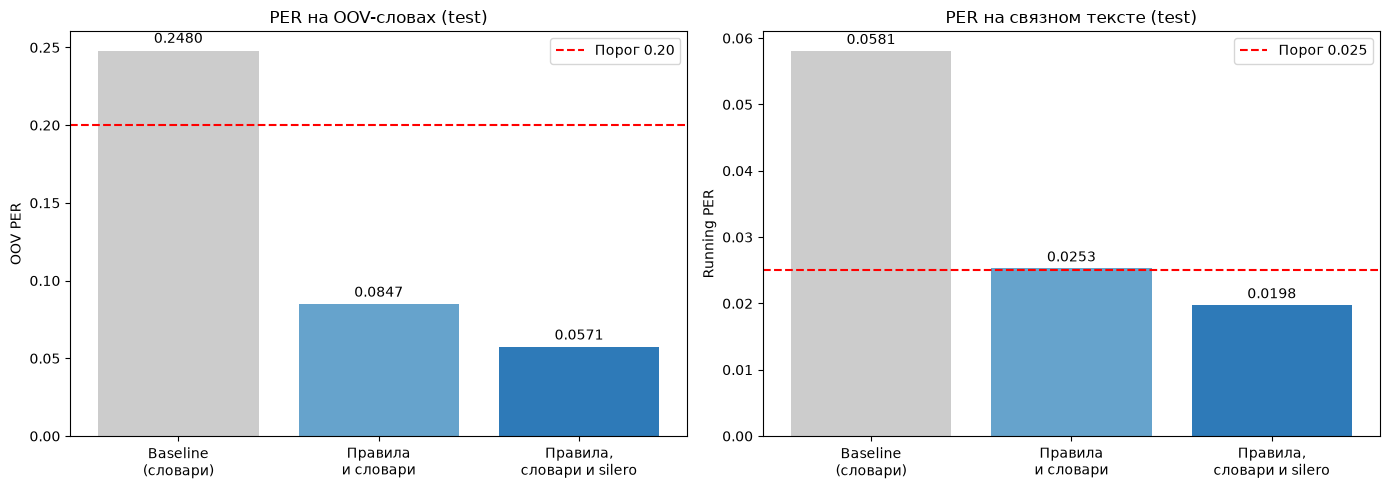

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
labels = ['Baseline\n(словари)', 'Правила\nи словари', 'Правила,\nсловари и silero']
oov_per = [results['baseline']['OOV_PER'],
           results['rules']['OOV_PER'],
           results['rules_silero']['OOV_PER']]
bars = ax.bar(labels, oov_per, color=['#cccccc', '#66a3cc', '#2e7ab8'])
ax.axhline(0.20, color='red', linestyle='--', label='Порог 0.20')
ax.set_ylabel('OOV PER')
ax.set_title('PER на OOV-словах (test)')
ax.legend()
for b, v in zip(bars, oov_per):
    ax.text(b.get_x() + b.get_width()/2, v + 0.005, f'{v:.4f}', ha='center')

ax = axes[1]
running = [results['baseline']['running_PER'],
           results['rules']['running_PER'],
           results['rules_silero']['running_PER']]
bars = ax.bar(labels, running, color=['#cccccc', '#66a3cc', '#2e7ab8'])
ax.axhline(0.025, color='red', linestyle='--', label='Порог 0.025')
ax.set_ylabel('Running PER')
ax.set_title('PER на связном тексте (test)')
ax.legend()
for b, v in zip(bars, running):
    ax.text(b.get_x() + b.get_width()/2, v + 0.001, f'{v:.4f}', ha='center')

plt.tight_layout()
plt.show()

## 4.  Подготовка метаданных для работы №4

1. **`data/metadata_phones_gt.csv`** — эталонная разметка (ground truth),
   собранная из `tokens_phones_sil.csv` обратно в предложения.
2. **`data/metadata_phones.csv`** — предсказанная разметка, предсказание G2P.

In [ ]:
result = subprocess.run(
    [sys.executable, 'prepare_metadata.py'],
    capture_output=True, text=True, cwd='.'
)
print(result.stdout)
if result.stderr:
    print('STDERR:', result.stderr)

target inventory: 56 phones
tokens_phones_sil: 271812 rows, 19673 sentences
lexicon: 38498 types, mfa: 452397 words

wrote data/metadata_phones_gt.csv (19673 rows)
wrote data/metadata_phones.csv (19673 rows)
metadata_phones_gt: все фонемы ∈ target
metadata_phones: все фонемы ∈ target

STDERR: 
GT: 100%|██████████| 19673/19673 [00:04<00:00, 4083.24it/s]

Pred: 100%|██████████| 19673/19673 [00:04<00:00, 4273.80it/s]



## 5. Выводы

### Итоговые метрики
| Модель | Running PER | OOV PER | OOV word acc |
|---|---|---|---|
| Baseline | 0.0581 | 0.2480 | 0.7543 |
| + правила | 0.0253 | 0.0847 | 0.7597 |
| + silero-stress | **0.0198** | **0.0571** | **0.7798** |

- Словари (`lexicon.csv` + MFA) - бэйзлайн: дает in-vocab PER 0.0104.
- Правила G2P для OOV: снижают OOV PER с 0.2480 до 0.0847
   (−66%), Running PER с 0.0581 до 0.0253. Помогают практически исключить ошибки на согласных звуках.
- `silero-stress` снижает OOV PER с 0.0847 до 0.0571, Running PER с 0.0253 до 0.0198 (−21%) за счет корректной расстановки ударений, от которой зависит редукция безударных гласных. Без `silero-stress` правила выдавали все гласные OOV-слова в полной форме, тогда как в эталонной разметке MFA безударные гласные редуцированы. Это давало систематическую ошибку на каждой безударной гласной. `silero-stress` определяет позицию ударения, что позволяет корректно редуцировать остальные гласные.